<h3><center><font size=10>Airbnb Case Study</center></font></h3>

<center><img src="https://logos-world.net/wp-content/uploads/2020/10/Airbnb-Logo.jpg" width="1080" height="300"></center>

# **Problem Statement**

### **Background**

Airbnb is an online platform that allows people to rent short-term accommodation. This ranges from regular people with a spare bedroom to property management firms who lease multiple rentals. On the one side, Airbnb enables owners to list their space and earn rental money. On the other side, it provides travelers easy access to renting private homes.

Airbnb receives commissions from two sources upon every booking, namely from the hosts and guests. For every booking, Airbnb charges the guest 6-12% of the booking fee. Moreover, Airbnb charges the host 3% for every successful transaction.

As a senior data scientist at Airbnb, you have to come up with a pricing model that can effectively predict the Rent for accommodation and can help hosts, travelers, and also the business in devising profitable strategies.

### **Objective**

To explore and visualize the data, build a **linear regression** model to predict the prices of Airbnb rental rooms, and generate a set of insights and recommendations that will help the business.

### **Data Description**

The data contains information about the different types of rental rooms offered by Airbnb over a fixed period of time. The detailed data dictionary is given below.

##### **Data Dictionary**
- id: Property ID
- room_type: Type of Room in the property
- accommodates: How many adults can this property accommodate
- bathrooms: Number of bathrooms on the property
- cancellation_policy: Cancellation policy of the property
- cleaning_fee: This denotes whether the property cleaning fee is included in the rent or not
- instant_bookable: It indicates whether an instant booking facility is available or not
- review_scores_rating: Review rating score of the property
- bedrooms: Number of bedrooms in the property
- beds: Total number of beds in the property
- log_price: Log of the rental price of the property for a fixed period. [If the price is 12000 dollars, then log_price represents log(12000)]

### **Importing necessary libraries**

In [1]:
#libraries for reading and manipulating data
import pandas as pd
import numpy as np

#libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

#libraries for data pre-processing
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

#library to split the data
from sklearn.model_selection import train_test_split

#libraries for model building
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm

#libraries to evaluate model performance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

#Other libraries
from scipy.stats import shapiro
from statsmodels.stats.outliers_influence import variance_inflation_factor

import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

### **Reading the dataset**

In [2]:
airbnb= pd.read_csv('Airbnb.csv')

In [3]:
#creating copy of the dataset to avoid changes to the original dataset
data= airbnb.copy()

## **Overview of the dataset**

In [4]:
#viewing first five rows of the dataset
data.head()

,id,room_type,accommodates,bathrooms,cancellation_policy,cleaning_fee,instant_bookable,review_scores_rating,bedrooms,beds,log_price
0,6901257,Entire home/apt,3.0,1.0,strict,True,f,100.0,1.0,1.0,5.010635
1,6304928,Entire home/apt,7.0,1.0,strict,True,t,93.0,3.0,3.0,5.129899
2,7919400,Entire home/apt,5.0,1.0,moderate,True,t,92.0,1.0,3.0,4.976734
3,13418779,Entire home/apt,4.0,1.0,flexible,True,f,NaN,2.0,2.0,6.620073
4,3808709,Entire home/apt,2.0,1.0,moderate,True,t,40.0,0.0,1.0,4.744932


In [5]:
#viewing last five rows of the dataset
data.tail()

,id,room_type,accommodates,bathrooms,cancellation_policy,cleaning_fee,instant_bookable,review_scores_rating,bedrooms,beds,log_price
74106,14549287,Private room,1.0,1.0,flexible,False,f,NaN,1.0,1.0,4.605170
74107,13281809,Entire home/apt,4.0,2.0,moderate,True,f,93.0,2.0,4.0,5.043425
74108,18688039,Entire home/apt,5.0,1.0,moderate,True,t,94.0,2.0,2.0,5.220356
74109,17045948,Entire home/apt,2.0,1.0,strict,True,t,NaN,0.0,2.0,5.273000
74110,3534845,Entire home/apt,4.0,1.0,moderate,False,f,96.0,1.0,2.0,4.852030


### **Understanding the shape of the dataset**

In [6]:
#viewing number of rows and columns in the dataset- (rows, columns)
data.shape

(74111, 11)

##### **Observation**-
- The dataset has 74111 rows and 11 columns

### **Checking data types of the columns and number of non-null values in the dataset**

In [7]:
#checking data types and non_null values
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74111 entries, 0 to 74110
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    74111 non-null  int64  
 1   room_type             74106 non-null  object 
 2   accommodates          74108 non-null  float64
 3   bathrooms             73908 non-null  float64
 4   cancellation_policy   74103 non-null  object 
 5   cleaning_fee          74107 non-null  object 
 6   instant_bookable      74111 non-null  object 
 7   review_scores_rating  57389 non-null  float64
 8   bedrooms              74019 non-null  float64
 9   beds                  73980 non-null  float64
 10  log_price             74111 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 6.2+ MB


##### **Observations**- 
- There are no null values in the id, instant_bookable and log_price column where as all other columns have some missing values.
- The room_type, cancellation_policy, cleaning_fee, instant_bookable are categorical columns of type- 'object'.
- The id column is of type integer.
- The accomodates, bathrooms, review_scores_rating, bedrooms, beds and log_price are of type- 'float64'.

We will drop id column as it is not adding any new information.

In [8]:
#dropping id column
data= data.drop('id', axis= 1)

### **Checking statistical summary of the data**

In [9]:
#Summarizing numerical data of the dataset
data.describe()

,accommodates,bathrooms,review_scores_rating,bedrooms,beds,log_price
count,74108.000000,73908.000000,57389.000000,74019.000000,73980.000000,74111.000000
mean,3.155125,1.235272,94.067365,1.265797,1.710868,4.782069
std,2.153603,0.582054,7.836556,0.852149,1.254142,0.717394
min,1.000000,0.000000,20.000000,0.000000,0.000000,0.000000
25%,2.000000,1.000000,92.000000,1.000000,1.000000,4.317488
50%,2.000000,1.000000,96.000000,1.000000,1.000000,4.709530
75%,4.000000,1.000000,100.000000,1.000000,2.000000,5.220356
max,16.000000,8.000000,100.000000,10.000000,18.000000,7.600402


##### **Observations**- 
- On an average, the accomodations listed on Airbnb can accomodates ~3 persons. Some accommodations can accommodate maximum upto 16 adults and minimum is 1 person.
- On an average, number of bathrooms, beds and bedrooms for an accomodation is ~1. 
- Ratings are in range of 20 to 100. The mean rating for an accomodation is ~94.
- On an average log_price is 4.7.

In [10]:
#Summarizing categorical data of the dataset
data.describe(include= 'object')

,room_type,cancellation_policy,cleaning_fee,instant_bookable
count,74106,74103,74107,74111
unique,3,3,2,2
top,Entire home/apt,strict,True,f
freq,41308,32500,54399,54660


##### **Observations**- 
- Nearly more than half of the accomodations listed on Airbnb are of type entire home / apartment.
- Most of the accomodations are not instantly bookable.
- Airbnb follows strict cancellation policy for some of the accomodations which is ~50% of the accomodations. 

### **Checking for missing values in the dataset**

In [11]:
#summing number of missing values
data.isna().sum().sort_values(ascending= False)

review_scores_rating    16722
bathrooms                 203
beds                      131
bedrooms                   92
cancellation_policy         8
room_type                   5
cleaning_fee                4
accommodates                3
instant_bookable            0
log_price                   0
dtype: int64

##### **Observations**- 
- There are missing values in the dataset for most of the columns except instant_bookable and log_price column.
- They need to be treated during data pre-processing.

### **Checking for duplicate values in the dataset**

In [12]:
#total number of duplicate rows in the data
data.duplicated().sum()

np.int64(19994)

##### **Observations**- 
- There are some duplicate rows in the dataset which we will treat after filling in the missing values.

### **Checking for unique values in the dataset**

In [13]:
#number of unique values in the dataset
data.nunique()

room_type                 3
accommodates             16
bathrooms                17
cancellation_policy       3
cleaning_fee              2
instant_bookable          2
review_scores_rating     54
bedrooms                 11
beds                     18
log_price               767
dtype: int64

### **Checking for unique categories for each column present in the dataset**

In [14]:
#printing count of each categorical level in the columns
cat_cols= data.select_dtypes(['object','category']).columns.tolist()
for col in cat_cols:
    print(data[col].value_counts())
    print("-" * 50)

room_type
Entire home/apt    41308
Private room       30635
Shared room         2163
Name: count, dtype: int64
--------------------------------------------------
cancellation_policy
strict      32500
flexible    22543
moderate    19060
Name: count, dtype: int64
--------------------------------------------------
cleaning_fee
True     54399
False    19708
Name: count, dtype: int64
--------------------------------------------------
instant_bookable
f    54660
t    19451
Name: count, dtype: int64
--------------------------------------------------


In [15]:
#printing percentage of each categorical level in the columns
cat_cols= data.select_dtypes(['object','category']).columns.tolist()
for col in cat_cols:
    print(data[col].value_counts(normalize= True))
    print("-" * 50)

room_type
Entire home/apt    0.557418
Private room       0.413394
Shared room        0.029188
Name: proportion, dtype: float64
--------------------------------------------------
cancellation_policy
strict      0.438579
flexible    0.304212
moderate    0.257210
Name: proportion, dtype: float64
--------------------------------------------------
cleaning_fee
True     0.73406
False    0.26594
Name: proportion, dtype: float64
--------------------------------------------------
instant_bookable
f    0.737542
t    0.262458
Name: proportion, dtype: float64
--------------------------------------------------


##### **Observations**- 
- There nearly 62% of accomodation type as Entire home / apartment listed on Airbnb.
- Most of the transactions have cleaning fee applied in the rent.
- Also, most of the bookings on Airbnb about 70% are instantly bookable.

## **Exploratory Data Analysis**

### **Univariate Analysis**

##### **Checking distribution for numerical columns**

In [16]:
def hist_box_plot(data, column):
    if column in data.columns:
        #setting axis for subplots
        fig, axes = plt.subplots(1, 2, figsize=(15, 5))
        #plotting histogram
        sns.histplot(data[column], ax= axes[0], color='red', kde= True)
        #setting title for the plots
        axes[0].set_title(f"Distribution of {column} column")
        #plotting box-plot
        sns.boxplot(data[column], ax= axes[1], color='red')
        #setting title for the plots
        axes[1].set_title(f"Box-plot of {column} column")
        plt.show() 

##### **Observations on accomodates column**

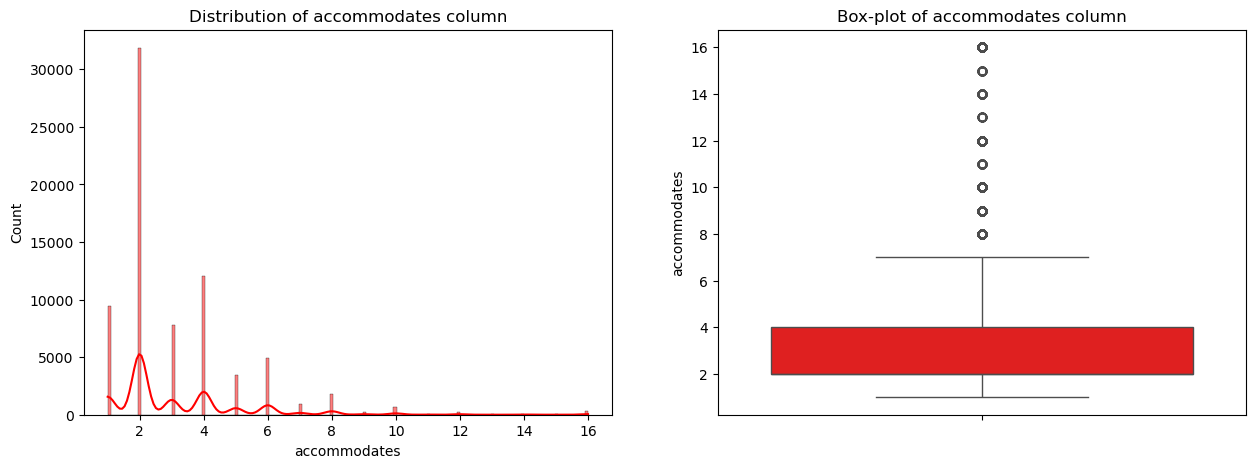

In [17]:
hist_box_plot(data, 'accommodates')

##### **Observations**- 
- Most of the properties can accomodate 2 adults.
- There are few outliers present in the column.
- Outliers are from accomodations that can accomodate 8-16 adults indicating large sized propertities.

##### **Observations on bathrooms column**

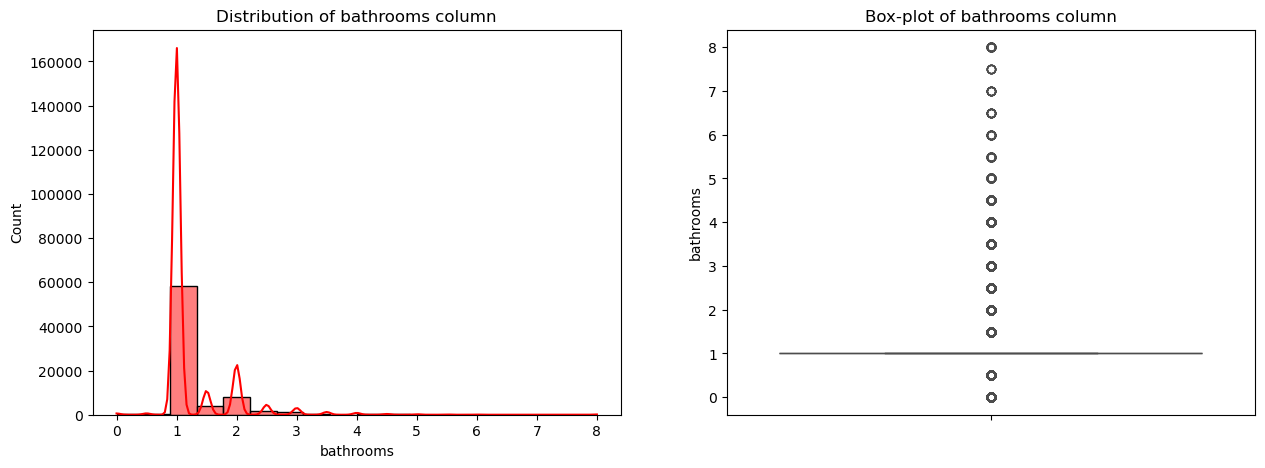

In [18]:
hist_box_plot(data, 'bathrooms')

##### **Observations**- 
- Most of the properties have 1 bathroom in an accomodation.
- There are some outliers present in the column.
- Outliers are from bathrooms that are more than 2 in number indicating very few accomodations have more than 2 bathrooms.

##### **Observations on review_scores_rating column**

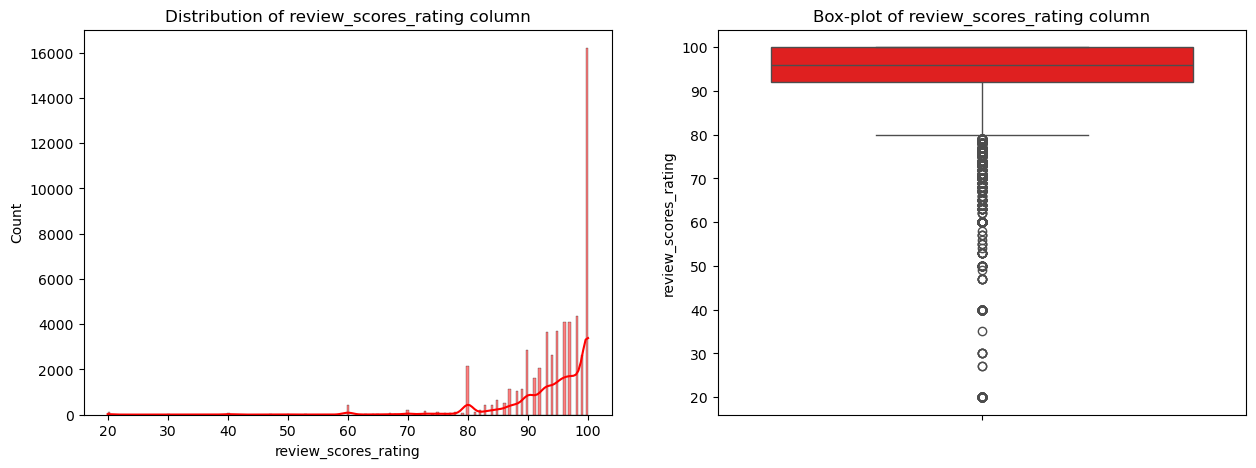

In [19]:
hist_box_plot(data, 'review_scores_rating')

##### **Observations**- 
- Most of the properties have rating between 90 - 100 as review score rating.
- There are some outliers present.
- Very ratings are below 80.

##### **Observations on bedrooms column**

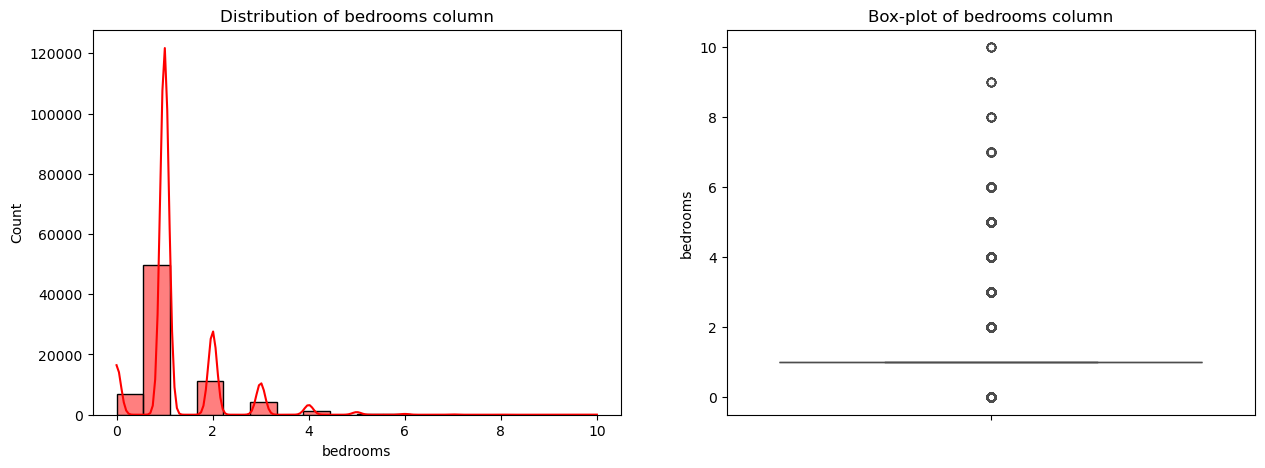

In [20]:
hist_box_plot(data, 'bedrooms')

##### **Observations**- 
- Most of the accomodations have 1 bedroom.
- There are some outliers present.
- Very few bedrooms are more than 4 in number.

##### **Observations on beds column**

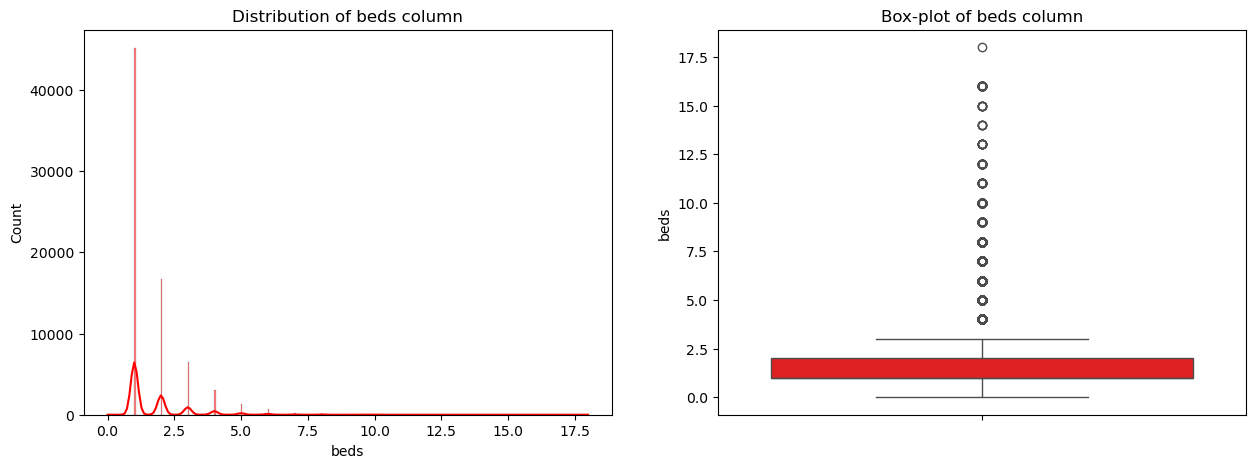

In [21]:
hist_box_plot(data, 'beds')

##### **Observations**- 
- Most of the beds are between ~1 - 2. 
- There are some outliers present.
- On average, number of beds range from 1 to 3 in number.

##### **Observations on log_price column**

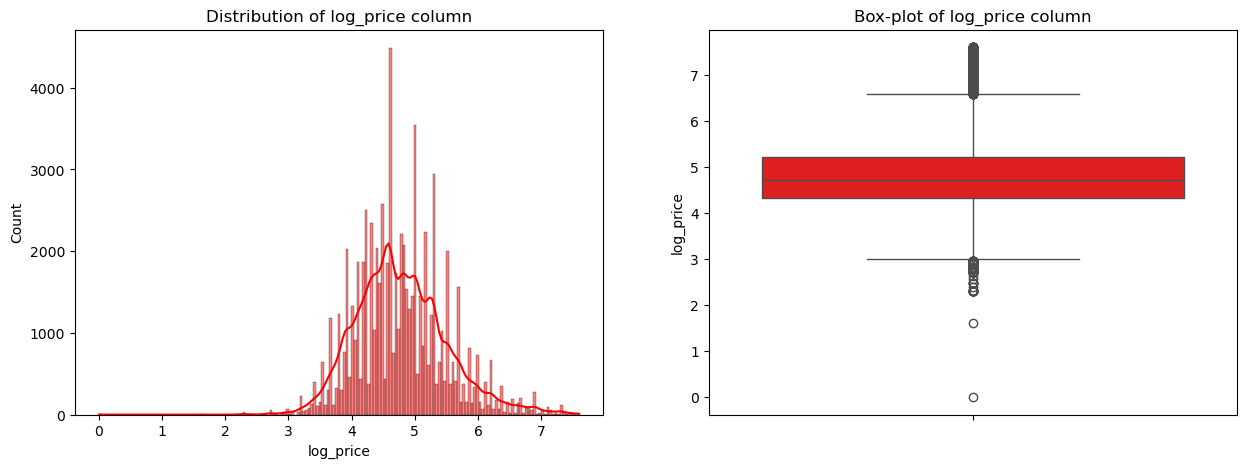

In [22]:
hist_box_plot(data, 'log_price')

##### **Observations**- 
- The distribution of log_price column is seemingly normal distribution with slight right skewness.
- There are many outliers present.
- On average, log_price range from 4.5 to 5.5.

##### **Checking skewness and kurtosis numerical columns**

In [23]:
#printing skewness and kurtosis in numerical columns
for col in data.select_dtypes(['int64', 'float64']).columns.tolist():
    print(f'{col}: \n Skewness= {data[col].skew():.2f}, Kurtosis= {data[col].kurt():.2f}')

accommodates: 
 Skewness= 2.23, Kurtosis= 7.43
bathrooms: 
 Skewness= 3.69, Kurtosis= 22.24
review_scores_rating: 
 Skewness= -3.38, Kurtosis= 20.02
bedrooms: 
 Skewness= 1.99, Kurtosis= 7.58
beds: 
 Skewness= 3.36, Kurtosis= 19.72
log_price: 
 Skewness= 0.51, Kurtosis= 0.66


##### **Observations**- 
- The accomodates, bathrooms, bedrooms and beds are right skewed as skewness is > 1 where review_scores_rating is negatively skewed.
- All the columns except log_price indicate heavy tails (may be due to outliers) having value > 3.

##### **Target variable analysis**

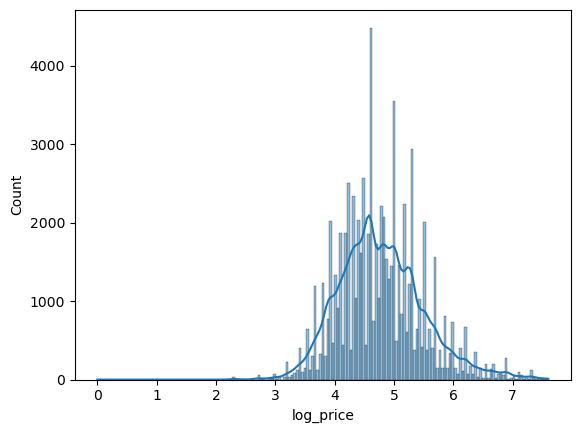

In [24]:
sns.histplot(data['log_price'], kde= True )
plt.show()

##### **Observations**- 
- The distribution of log_price column is seemingly normal distribution with slight right skewness.
- On average, log_price range from 4.5 to 5.5.

##### **Normality test for target variable**

In [25]:
stat, p= shapiro(data['log_price'])
print(f'Statistic= {stat:.5f}, p= {p:.5f}')

Statistic= 0.98376, p= 0.00000


##### **Observations**- 
- The statistic (W) has a value close to 1 depicts  a normal distribution.
- But, p-value < 0.05 shows some deviation in the data.
- Since, dataset is quite large, we would consider it to be normal.

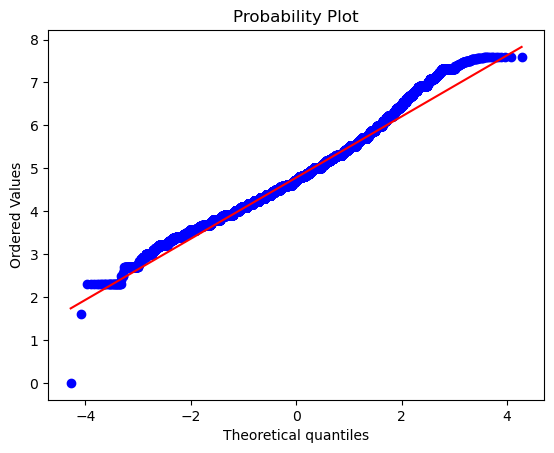

In [26]:
stats.probplot(data['log_price'],dist='norm',plot=plt)
plt.show()

##### **Observations**- 
- Since, data points follow the diagonal, we will consider target variable to follow normal distribution.

##### **Checking visualizations for categorical columns**

In [27]:
def count_plot(data):
    #selecting categorical columns
    cat_cols= data.select_dtypes(['object','category']).columns.tolist() 
    #setting axis for subplots
    fig, axes= plt.subplots(2,2,figsize=(16,12))
    axes= axes.flatten()
    for i, col in enumerate(cat_cols):
        #plotting count-plot for categorical columns
        sns.countplot(data= data, x=col, ax= axes[i], palette= 'hls', orient= 'v')
        plt.tight_layout()
        #setting title for plots
        axes[i].set_title(f"Number of properties for {col}")
        #setting x-label for plots
        axes[i].set_xlabel(col)
    plt.show() 

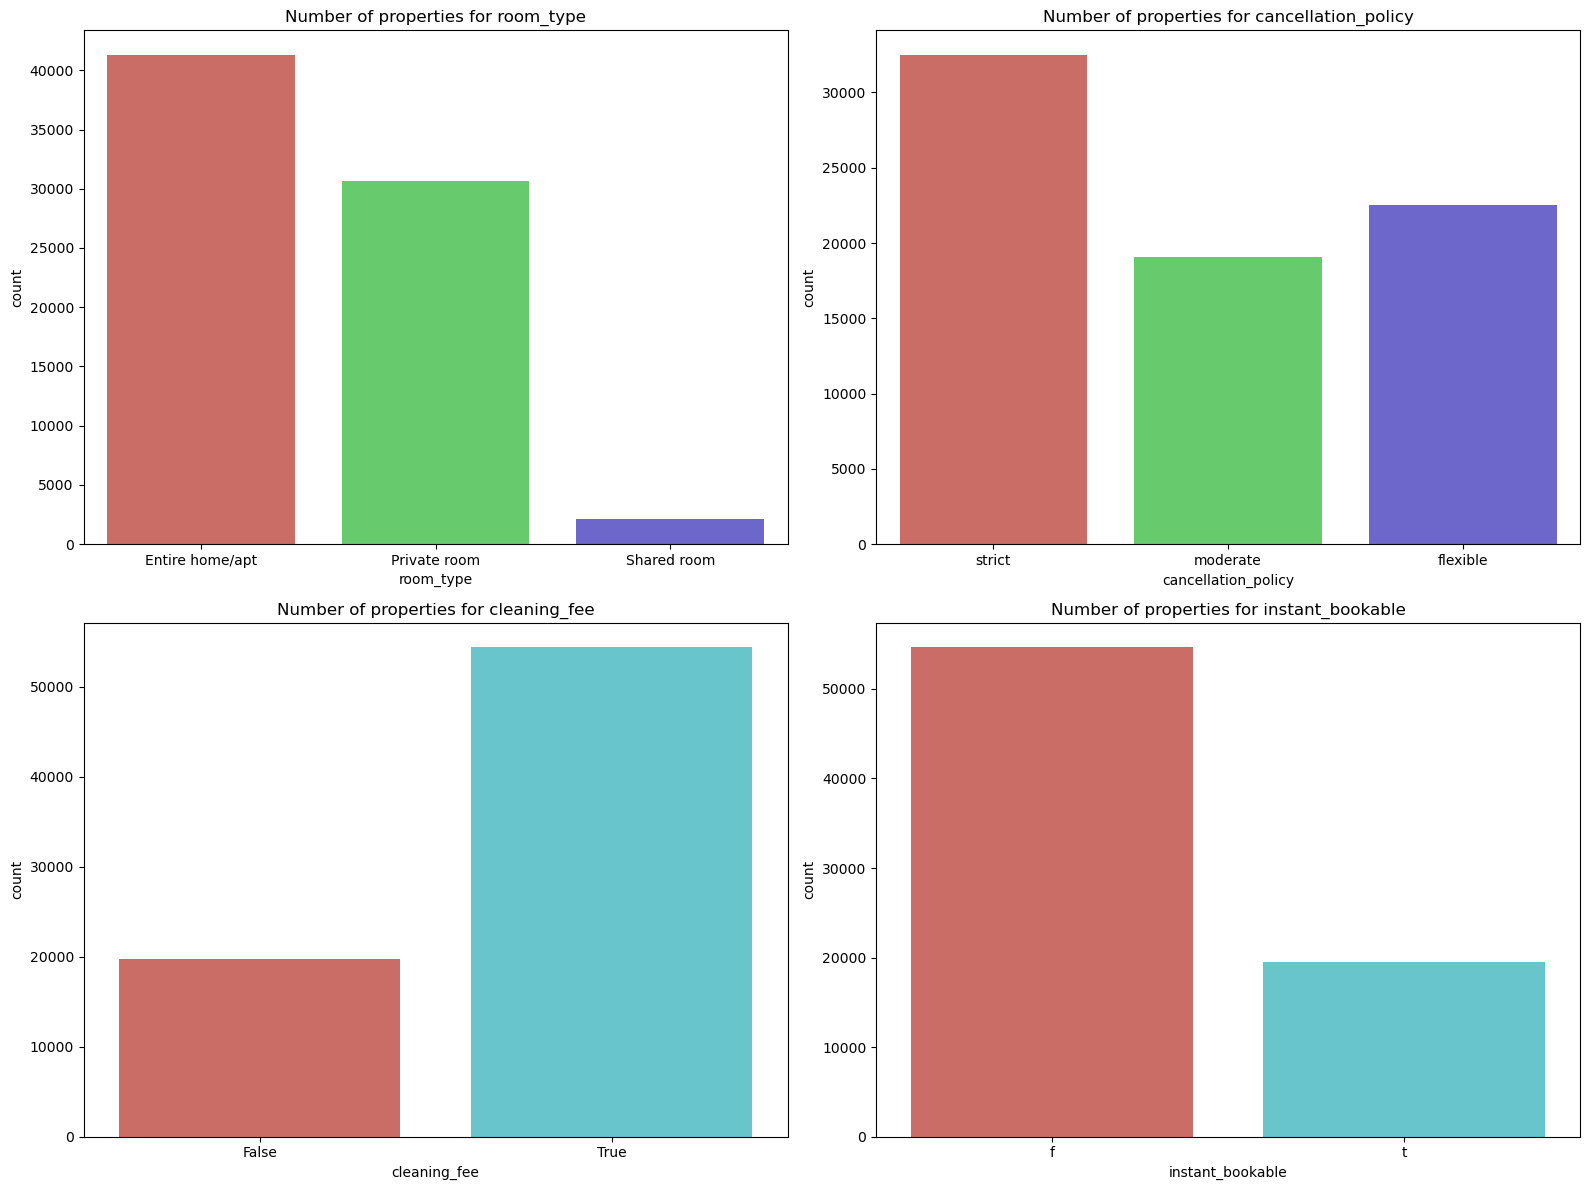

In [28]:
count_plot(data)

##### **Observations**- 
- Most of customers prefer the accomodations which are of type entire home / apartment.
- Very less customers prefer shared rooms.
- Most of accomodations have strict cancellation policy.
- Around 20% - 30% accomodations have moderate and flexible policies.
- Most of the accomodations have cleaning fee included in the rent.
- Only about 26% accomodations can be instantly booked. 

### **Bivariate Analysis**

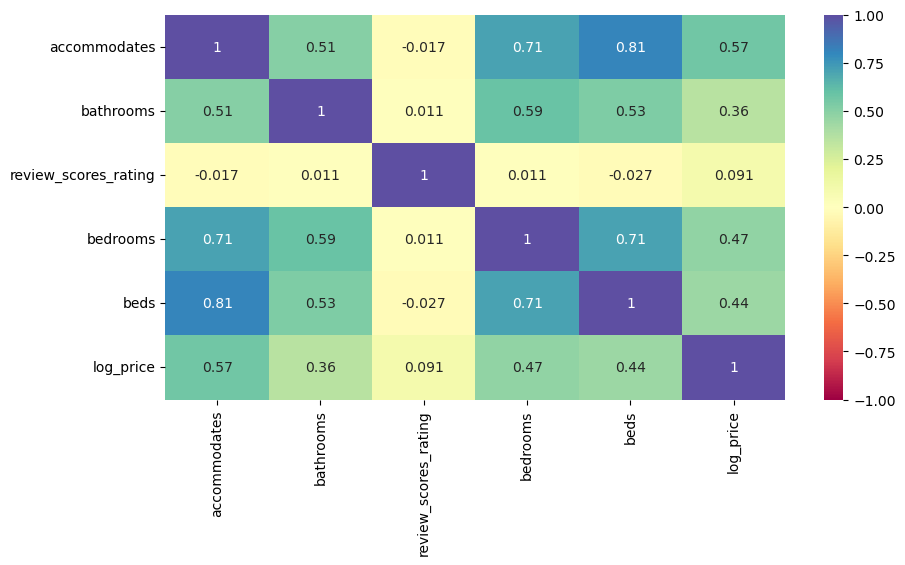

In [29]:
#displaying correlation matrix
plt.figure(figsize=(10,5))
corr_matrix= data.corr(numeric_only= True)
#displaying heatmap for the correlation-matrix
sns.heatmap(corr_matrix,annot=True,cmap='Spectral',vmin=-1,vmax=1)
plt.show()

##### **Observations**- 
- There is high correlation between number of beds and number of adults the accomodation can accomodate.
- Number of beds have a good positive correlation with number of bedrooms.
- The price of the accomodation is correlated with number of adults an accomodation can accomodate.
- Number of beds, bedrooms and number of adults that a accomodation are related to each other shown by correlation values.
- Suprisingly, rating has less effect on the price of the accomodation.

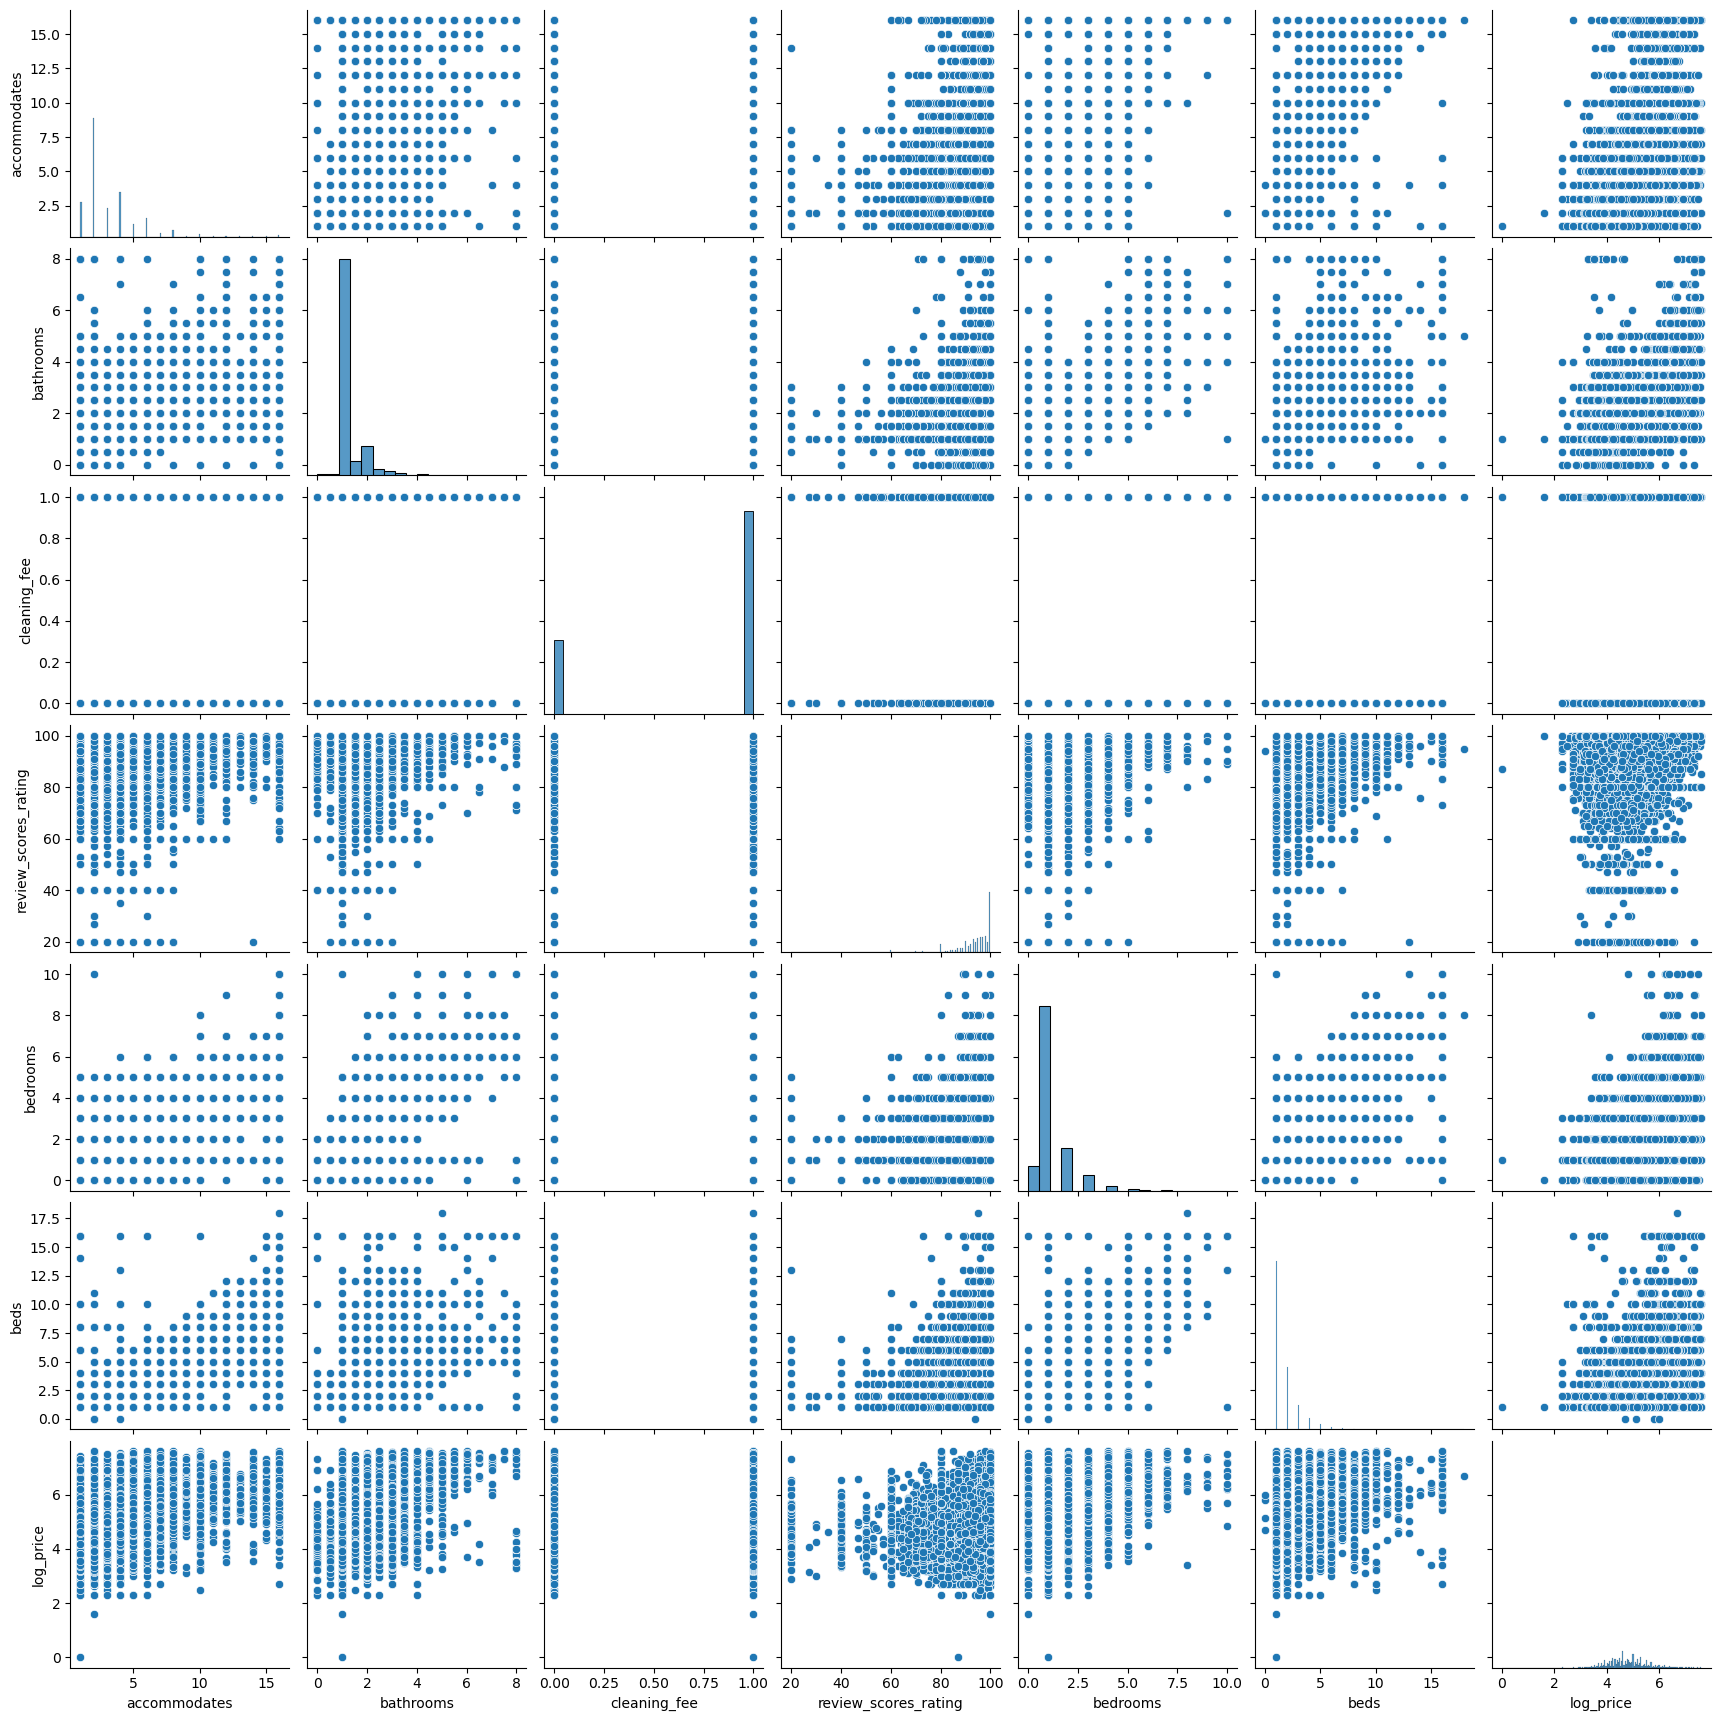

In [30]:
sns.pairplot(data, palette= 'mako')
plt.show()

##### **Observations**- 
- Price is correlated positively with number of adults an accomodation can accomodate, number of bedrooms and number of beds. This indicates that
  space of an accomodation is related positively with the price of the accomodation.
- Review_scores_rating and price are weakly correlated.

##### **Variation of different variables with Target variable i.e. log_price column**

In [31]:
def scatter_plot(data):
    #selecting numerical columns
    num_cols= data.select_dtypes(['int64','float64']).columns.tolist() 
    #setting the axis for subplots
    fig, axes= plt.subplots(2,3,figsize=(20,12))
    axes= axes.flatten()
    for i, col in enumerate(num_cols):
        #plotting scatter-plot for target variable and other numeric features
        sns.scatterplot(x= col,y= 'log_price',data= data, ax= axes[i], palette= 'tab10')
        plt.tight_layout()
        #setting the title for the plots
        axes[i].set_title(f"{col} by log_price")
        #setting the x-label for the plots
        axes[i].set_xlabel(col)
        #setting the y-label for the plots
        axes[i].set_ylabel('log_price')
    plt.show()

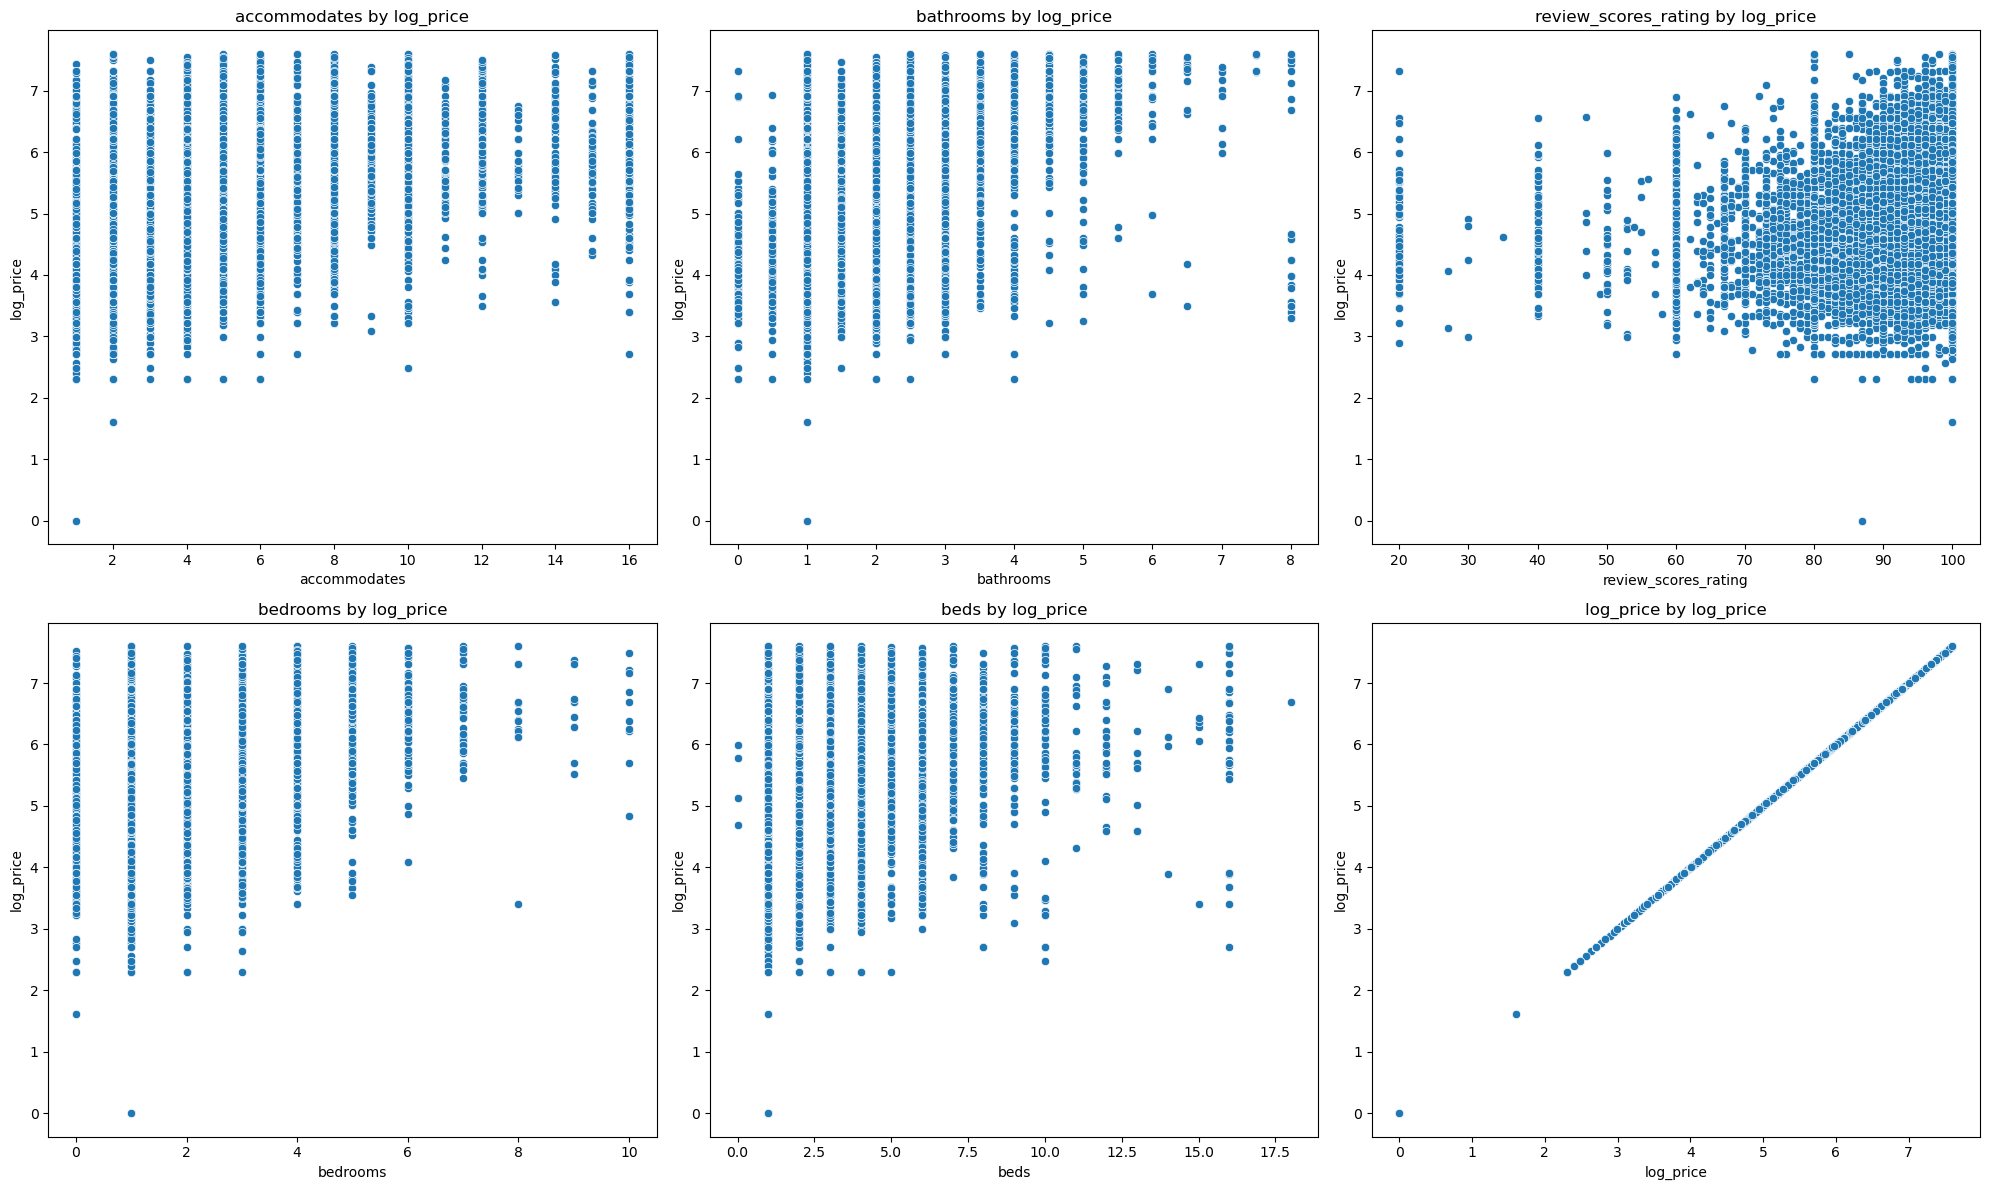

In [32]:
scatter_plot(data)

##### **Observations**- 
- Price is correlated positively with number of adults an accomodation can accomodate, number of bedrooms and number of beds. This indicates that
  space of an accomodation is related positively with the price of the accomodation.
- Review_scores_rating has a funnel shaped distribution depicting heteroscedasticity.

In [33]:
def box_plot(data):
    #selecting categorical features
    cat_cols= data.select_dtypes(['object','category']).columns.tolist() 
    #setting axis for the subplots
    fig, axes= plt.subplots(2,2,figsize=(16,12))
    axes= axes.flatten()
    for i, col in enumerate(cat_cols):
        #plotting the box-plot
        sns.boxplot(x= col,y= 'log_price',data= data, ax= axes[i], hue= col, palette= 'mako')
        plt.tight_layout()
        #setting the title for box-plot
        axes[i].set_title(f"log price by {col}")
        #setting the x-label for box-plot
        axes[i].set_xlabel(col)
        #setting the y-label for box-plot
        axes[i].set_ylabel('log_price')
    plt.show()

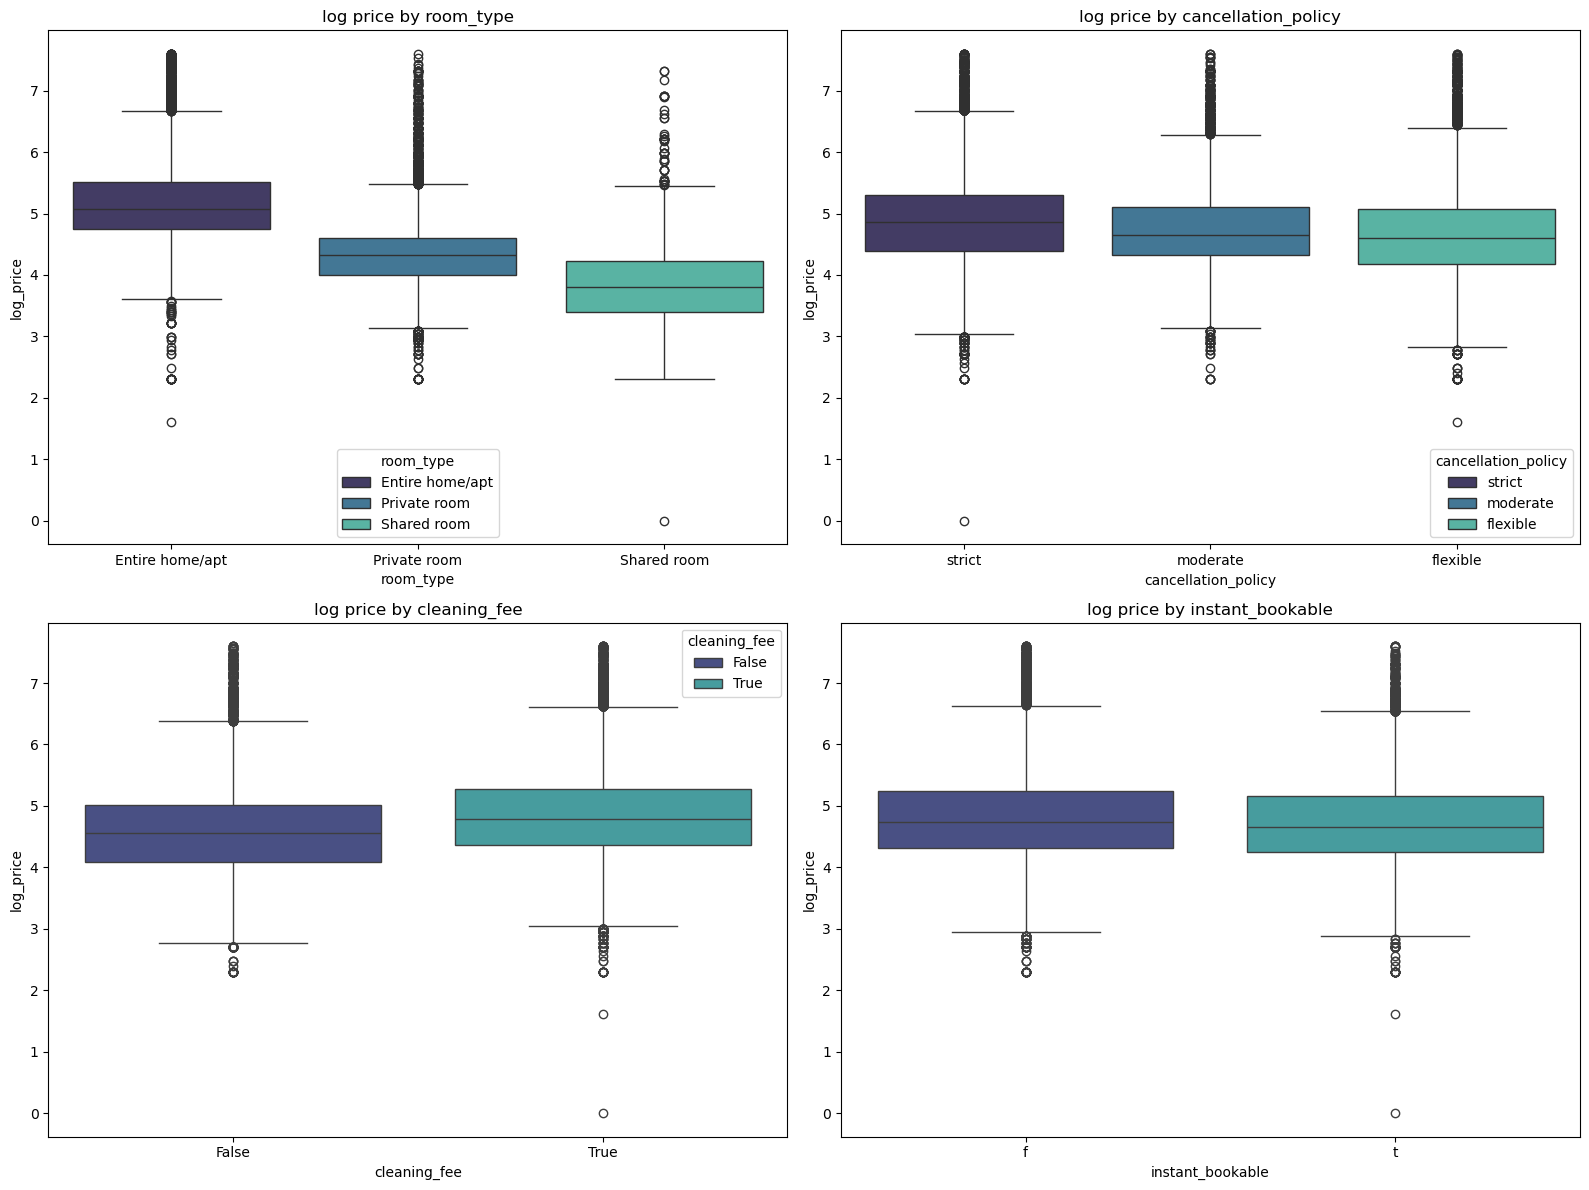

In [34]:
box_plot(data)

##### **Observations**- 
- Prices for accomodation of type entire home/ apartment are more.
- Rent for accomodation for strict cancellation policies also tends to be little higher than moderate and flexible policy accomodations.

##### **Summarizing average log_price by each category**

In [35]:
def mean_target_plot(data):
    #selecting the categorical features
    cat_cols= data.select_dtypes(['object','category']).columns.tolist()
    #setting axis for subplots
    fig, axes= plt.subplots(2,2,figsize=(20,12))
    axes= axes.flatten()
    for i, col in enumerate(cat_cols):
        #mean log_price values vs categorical features
        data.groupby(col)['log_price'].mean().sort_values(ascending= False).plot(kind='bar', ax= axes[i], color= 'red')
        plt.tight_layout()
        #setting title for the subplots
        axes[i].set_title(f"Mean log_price by {col}")
        #setting x-label for subplots
        axes[i].set_xlabel(col)
        #setting y-label for subplots
        axes[i].set_ylabel('log_price')
    plt.show()

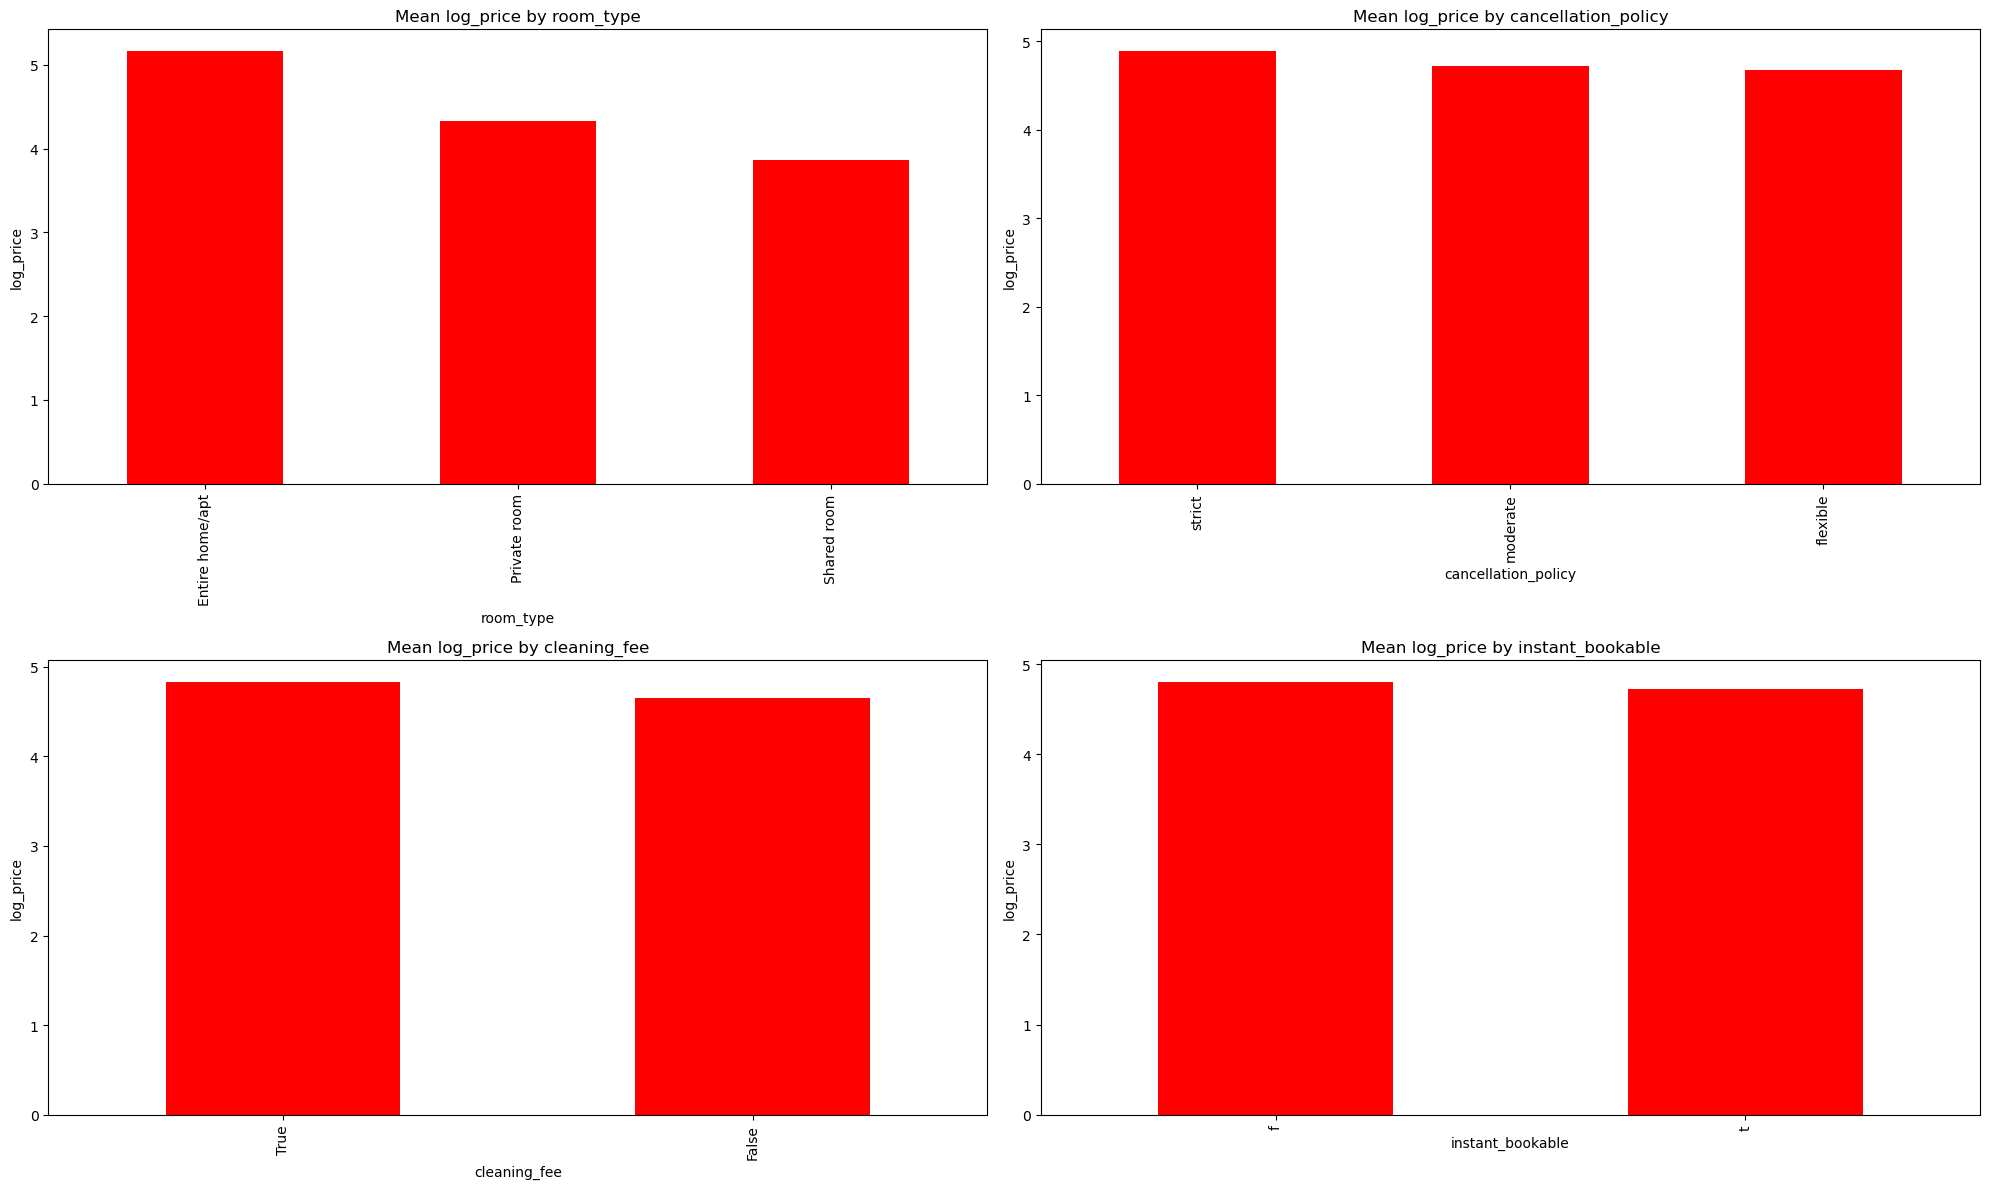

In [36]:
mean_target_plot(data)

##### **Observations**- 
- Mean log prices are higher for: 
- entire home/apartment, strict cancellation policies, cleaning fee is applied and for accomodations which are not instantly bookable.

##### **Quantifying for multi-collinearity in numerical columns**

In [37]:
#selecting numerical columns
num_cols= data.select_dtypes(['int64','float64']).columns.tolist() 
#dropping missing values for calculation purposes
X_vif= data[num_cols].dropna()
#creating the dataframe
vif= pd.DataFrame(
    {'Variable': X_vif.columns,
     'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1]) ]
    }
)
vif

,Variable,VIF
0,accommodates,13.029660
1,bathrooms,8.880842
2,review_scores_rating,50.170280
3,bedrooms,8.218858
4,beds,9.994187
5,log_price,64.770013


##### **Observations**- 
- Columns bathrooms, bedrooms, beds have moderate multicollinearity (5-10).
- review_scores_rating and accomodates have high multicollinearity.

### **Data Pre-processing**

In [38]:
#Mapping values f to False and t to True (their implied meanings)
data['instant_bookable']= data['instant_bookable'].map({'f': False, 't': True})

#### **Missing value treatment**

In [39]:
#Count of missing values
data.isna().sum().sort_values(ascending= False)

review_scores_rating    16722
bathrooms                 203
beds                      131
bedrooms                   92
cancellation_policy         8
room_type                   5
cleaning_fee                4
accommodates                3
instant_bookable            0
log_price                   0
dtype: int64

In [40]:
#percentage of missing values
(data.isnull().sum() / len(data) * 100).sort_values(ascending= False)

review_scores_rating    22.563452
bathrooms                0.273913
beds                     0.176762
bedrooms                 0.124138
cancellation_policy      0.010795
room_type                0.006747
cleaning_fee             0.005397
accommodates             0.004048
instant_bookable         0.000000
log_price                0.000000
dtype: float64

##### **Observations**- 
- Since, most of the missing values are less than 30%, we can impute them

In [41]:
#imputing missing 'review_scores_rating' values with the respective median
data['review_scores_rating']=data['review_scores_rating'].fillna(data['review_scores_rating'].median())

In [42]:
#imputing missing 'bathrooms' values with the respective median
data['bathrooms']=data['bathrooms'].fillna(data['bathrooms'].median())

In [43]:
#imputing missing 'bedrooms' values with the respective median
data['bedrooms']=data['bedrooms'].fillna(data['bedrooms'].median())

In [44]:
#imputing missing 'beds' values with the respective median
data['beds']=data['beds'].fillna(data['beds'].median())

In [45]:
#imputing missing 'accommodates' values with the respective median
data['accommodates']=data['accommodates'].fillna(data['accommodates'].median())

In [46]:
#imputing missing 'room_type' values with the respective mode
data['room_type']=data['room_type'].fillna(data['room_type'].mode()[0])

In [47]:
#imputing missing 'cancellation_policy' values with the respective mode
data['cancellation_policy']=data['cancellation_policy'].fillna(data['cancellation_policy'].mode()[0])

In [48]:
#imputing missing 'cleaning_fee' values with the respective mode
data['cleaning_fee']=data['cleaning_fee'].fillna(data['cleaning_fee'].mode()[0])

In [49]:
#checking sum of duplicated rows
data.duplicated().sum()

np.int64(21144)

In [50]:
#dropping number of duplicates
data= data.drop_duplicates()

In [51]:
#confirming sum of duplicated rows
data.duplicated().sum()

np.int64(0)

##### **Observations**- 
- Since, most of the variables have skewed distribution, we have replaced numerical variables with the median and categorical variables with mode.

In [52]:
#Verifying if the values are imputed 
data.isnull().sum()

room_type               0
accommodates            0
bathrooms               0
cancellation_policy     0
cleaning_fee            0
instant_bookable        0
review_scores_rating    0
bedrooms                0
beds                    0
log_price               0
dtype: int64

#### **Outlier Detection and Treatment**

In [53]:
#selecting numerical columns
num_cols= data.select_dtypes(['int64', 'float64']).columns.tolist()
for col in num_cols:
    #calculating quantile 0.25 for each column
   q1= data[col].quantile(0.25)
    #calculating quantile 0.75 for each column
   q3= data[col].quantile(0.75)
    #calculating inter-quartile range
   iqr= q3 - q1
   #calculating lower and upper bounds for the data
   lower_bound= q1 - 1.5 * iqr
   upper_bound= q3 + 1.5 * iqr
    #removing the data more than upper bound and lesser than lower bound
   data = data[(data[col] >= lower_bound) & (data[col] <= upper_bound)]

In [54]:
#checking shape of the data after removal of outliers
data.shape

(23285, 10)

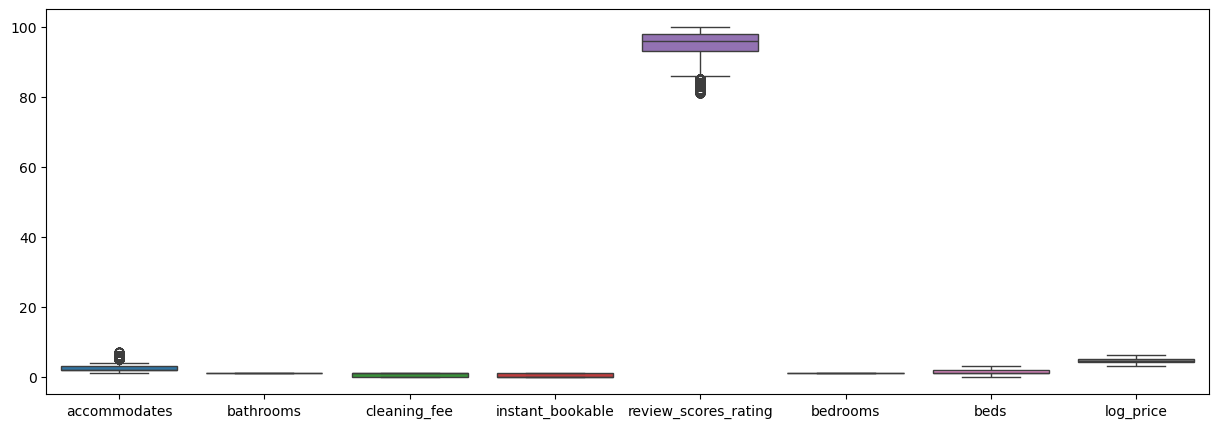

In [55]:
#plotting box-plot to check if outliers were removed
plt.figure(figsize=(15, 5))
sns.boxplot(data= data)
plt.show()

##### **Observations**- 
- Some outliers are still in the variables but we would not remove them for computation purposes.

#### **Feature Engineeering**

In [56]:
#Combining bedrooms and bathrooms for the estimation of total rooms.
data['total_rooms']= (data['bathrooms'] + data['bedrooms'])

In [57]:
#categorizing review_scores_rating column into categories- 'Low', 'Medium' and 'High'
bins= [20, 60, 80, 100]
labels= ['Low', 'Medium', 'High']
data['review_score_category']= pd.cut(data['review_scores_rating'], bins= bins, labels= labels, include_lowest= True)

In [58]:
#Creating new variable for number of bathrooms per guest
data['bathrooms_per_guest']= (data['bathrooms'] / data['accommodates'])

In [59]:
#confirming the new variables in the dataset and their types
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 23285 entries, 0 to 74110
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   room_type              23285 non-null  object  
 1   accommodates           23285 non-null  float64 
 2   bathrooms              23285 non-null  float64 
 3   cancellation_policy    23285 non-null  object  
 4   cleaning_fee           23285 non-null  bool    
 5   instant_bookable       23285 non-null  bool    
 6   review_scores_rating   23285 non-null  float64 
 7   bedrooms               23285 non-null  float64 
 8   beds                   23285 non-null  float64 
 9   log_price              23285 non-null  float64 
 10  total_rooms            23285 non-null  float64 
 11  review_score_category  23285 non-null  category
 12  bathrooms_per_guest    23285 non-null  float64 
dtypes: bool(2), category(1), float64(8), object(2)
memory usage: 2.0+ MB


#### **Storing data as features and target variable**

In [60]:
#separating features from label
#target
y= data['log_price']
#predictors
X= data.drop('log_price', axis=1)

#### **Categorical data encoding**

In [61]:
#encoding categorical variables
X= pd.get_dummies(data= X, columns= ['room_type','cancellation_policy','cleaning_fee','instant_bookable', 'review_score_category'], drop_first= True).astype('float')
X.head()

,accommodates,bathrooms,review_scores_rating,bedrooms,beds,total_rooms,bathrooms_per_guest,room_type_Private room,room_type_Shared room,cancellation_policy_moderate,cancellation_policy_strict,cleaning_fee_True,instant_bookable_True,review_score_category_Medium,review_score_category_High
0,3.0,1.0,100.0,1.0,1.0,2.0,0.333333,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
2,5.0,1.0,92.0,1.0,3.0,2.0,0.200000,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0
5,2.0,1.0,100.0,1.0,1.0,2.0,0.500000,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0
6,3.0,1.0,97.0,1.0,1.0,2.0,0.333333,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0
7,2.0,1.0,93.0,1.0,1.0,2.0,0.500000,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0


#### **Scaling the data**

In [62]:
#Instantiating StandardScaler
scaler= StandardScaler()
#fitting and transforming features
X_scaled= scaler.fit_transform(X)
#storing as a dataframe
X= pd.DataFrame(X_scaled, columns= X.columns)
X.head()

,accommodates,bathrooms,review_scores_rating,bedrooms,beds,total_rooms,bathrooms_per_guest,room_type_Private room,room_type_Shared room,cancellation_policy_moderate,cancellation_policy_strict,cleaning_fee_True,instant_bookable_True,review_score_category_Medium,review_score_category_High
0,0.443936,0.0,1.183689,0.0,-0.599885,0.0,-0.654156,-0.957814,-0.224261,-0.649604,1.177390,0.632864,-0.670526,0.0,0.0
1,2.248118,0.0,-0.693765,0.0,2.990020,0.0,-1.208013,-0.957814,-0.224261,1.539401,-0.849336,0.632864,1.491367,0.0,0.0
2,-0.458154,0.0,1.183689,0.0,-0.599885,0.0,0.038165,1.044044,-0.224261,-0.649604,1.177390,0.632864,1.491367,0.0,0.0
3,0.443936,0.0,0.479644,0.0,-0.599885,0.0,-0.654156,-0.957814,-0.224261,1.539401,-0.849336,0.632864,1.491367,0.0,0.0
4,-0.458154,0.0,-0.459083,0.0,-0.599885,0.0,0.038165,-0.957814,-0.224261,1.539401,-0.849336,0.632864,-0.670526,0.0,0.0


#### **Splitting data into train and test sets**

In [63]:
#splitting the data into train and test datasets
#20% of the data is used for testing
#random seed is 1
X_train, X_test, y_train, y_test= train_test_split(X, y, test_size=0.2, random_state=1)

In [64]:
#Number of rows in train and test sets
print("Number of rows in train set: ", X_train.shape[0])
print("Number of rows in test set: ", X_test.shape[0])

Number of rows in train set:  18628
Number of rows in test set:  4657


### **Model Building**

#### **Simple Linear Regression- accommodates vs log_price**

In [65]:
#Variable1
var1= ['accommodates']

In [66]:
#Instantiating and fitting the model
model1= LinearRegression()
model1.fit(X_train[var1], y_train)

LinearRegression()

In [67]:
# printing the linear regression coefficients
print( "Slope:", model1.coef_, "Intercept:", model1.intercept_)

Slope: [0.20500694] Intercept: 4.604264269684963


In [68]:
# printing the linear regression equation
print("log_price =", "(",model1.coef_[0],")","*",var1[0], "+", model1.intercept_)

log_price = ( 0.20500694138459669 ) * accommodates + 4.604264269684963


#### **Simple Linear Regression- bathrooms vs log_price**

In [69]:
#Variable2
var2= ['bathrooms']

In [70]:
#Instantiating and fitting the model
model2= LinearRegression()
model2.fit(X_train[var2], y_train)

LinearRegression()

In [71]:
# printing the linear regression coefficients
print( "Slope:", model2.coef_, "Intercept:", model2.intercept_)

Slope: [0.] Intercept: 4.605884485302877


In [72]:
# printing the linear regression equation
print("log_price =", "(",model2.coef_[0],")","*",var2[0], "+", model2.intercept_)

log_price = ( 0.0 ) * bathrooms + 4.605884485302877


#### **Simple Linear Regression- review_scores_rating vs log_price**

In [73]:
#Variable3
var3= ['review_scores_rating']

In [74]:
#Instantiating and fitting the model
model3= LinearRegression()
model3.fit(X_train[var3], y_train)

LinearRegression()

In [75]:
# printing the linear regression coefficients
print( "Slope:", model3.coef_, "Intercept:", model3.intercept_)

Slope: [0.06833321] Intercept: 4.606104871684277


In [76]:
# printing the linear regression equation
print("log_price =", "(",model3.coef_[0],")","*",var3[0], "+", model3.intercept_)

log_price = ( 0.06833320941671818 ) * review_scores_rating + 4.606104871684277


#### **Simple Linear Regression- bedrooms vs log_price**

In [77]:
#Variable4
var4= ['bedrooms']

In [78]:
#Instantiating and fitting the model
model4= LinearRegression()
model4.fit(X_train[var4], y_train)

LinearRegression()

In [79]:
# printing the linear regression coefficients
print( "Slope:", model4.coef_, "Intercept:", model4.intercept_)

Slope: [0.] Intercept: 4.605884485302877


In [80]:
# printing the linear regression equation
print("log_price =", "(",model4.coef_[0],")","*",var4[0], "+", model4.intercept_)

log_price = ( 0.0 ) * bedrooms + 4.605884485302877


#### **Simple Linear Regression- beds vs log_price**

In [81]:
##Variable5
var5= ['beds']

In [82]:
#Instantiating and fitting the model
model5= LinearRegression()
model5.fit(X_train[var5], y_train)

LinearRegression()

In [83]:
# printing the linear regression coefficients
print( "Slope:", model5.coef_, "Intercept:", model5.intercept_)

Slope: [0.09330465] Intercept: 4.605386404535434


In [84]:
# printing the linear regression equation
print("log_price =", "(",model5.coef_[0],")","*",var5[0], "+", model5.intercept_)

log_price = ( 0.09330464969790123 ) * beds + 4.605386404535434


#### **Simple Linear Regression- total_rooms vs log_price**

In [85]:
#Variable6
var6= ['total_rooms']

In [86]:
#Instantiating and fitting the model
model6= LinearRegression()
model6.fit(X_train[var6], y_train)

LinearRegression()

In [87]:
# printing the linear regression coefficients
print( "Slope:", model6.coef_, "Intercept:", model6.intercept_)

Slope: [0.] Intercept: 4.605884485302877


In [88]:
# printing the linear regression equation
print("log_price =", "(",model6.coef_[0],")","*",var6[0], "+", model6.intercept_)

log_price = ( 0.0 ) * total_rooms + 4.605884485302877


#### **Multiple Linear Regression- accommodates, beds  vs log_price**

In [89]:
#Variables7
var7= ['accommodates', 'beds']

In [90]:
#Instantiating and fitting the model
model7= LinearRegression()
model7.fit(X_train[var7], y_train)

LinearRegression()

In [91]:
# printing the linear regression coefficients
print( "Slope:", model7.coef_, "Intercept:", model7.intercept_)

Slope: [ 0.2247243  -0.03455312] Intercept: 4.6042928911600365


In [92]:
# printing the linear regression equation
print("log_price =", "(",model7.coef_[0],")","*",var7[0], "+", "(",model7.coef_[1],")","*",var7[1], "+" ,model7.intercept_)

log_price = ( 0.22472430051012582 ) * accommodates + ( -0.034553120305690445 ) * beds + 4.6042928911600365


#### **Multiple Linear Regression- accommodates, beds, review_scores_rating  vs log_price**

In [93]:
#Variables8
var8= ['accommodates', 'beds', 'review_scores_rating']

In [94]:
#Instantiating and fitting the model
model8= LinearRegression()
model8.fit(X_train[var8], y_train)

LinearRegression()

In [95]:
# printing the linear regression coefficients
print( "Slope:", model8.coef_, "Intercept:", model8.intercept_)

Slope: [ 0.2270218  -0.0358283   0.07317243] Intercept: 4.604517534365875


In [96]:
# printing the linear regression equation
print("log_price =", "(",model8.coef_[0],")","*",var8[0], "+", "(",model8.coef_[1],")","*",var8[1], "+" ,
      "(",model8.coef_[2],")","*",var8[2], "+", model8.intercept_)

log_price = ( 0.22702180068882463 ) * accommodates + ( -0.035828295453503134 ) * beds + ( 0.07317242836759358 ) * review_scores_rating + 4.604517534365875


#### **Multiple Linear Regression- log_price vs all independent variables**

In [97]:
#Instantiating and fitting the model
model9= LinearRegression()
model9.fit(X_train, y_train)

LinearRegression()

In [98]:
# printing the linear regression coefficients
print(
    "Coefficients:", model9.coef_, model9.intercept_
)

Coefficients: [ 3.72027366e-02 -2.77555756e-17  6.56812316e-02 -1.38777878e-17
 -1.37427197e-02  0.00000000e+00 -5.98676460e-02 -2.51506509e-01
 -1.69726506e-01 -1.26246931e-02  1.12965464e-02 -1.62587637e-03
 -2.68807182e-02  0.00000000e+00  0.00000000e+00] 4.604400307224179


In [99]:
# printing the linear regression equation
regression_equation = "log_price = ( " + str(model9.coef_[0]) + " ) * " + X_train.columns.tolist()[0]
for i in range(1, model9.coef_.shape[0]):
    regression_equation += " + ( " + str(model9.coef_[i]) + " ) * " + X_train.columns.tolist()[i]
regression_equation +=  " + " + str(model9.intercept_)
print(regression_equation)

log_price = ( 0.03720273658402515 ) * accommodates + ( -2.7755575615628914e-17 ) * bathrooms + ( 0.06568123161139226 ) * review_scores_rating + ( -1.3877787807814457e-17 ) * bedrooms + ( -0.01374271966010652 ) * beds + ( 0.0 ) * total_rooms + ( -0.059867646015560466 ) * bathrooms_per_guest + ( -0.251506509352654 ) * room_type_Private room + ( -0.16972650550697024 ) * room_type_Shared room + ( -0.012624693134760504 ) * cancellation_policy_moderate + ( 0.011296546369149361 ) * cancellation_policy_strict + ( -0.0016258763745906001 ) * cleaning_fee_True + ( -0.026880718211690226 ) * instant_bookable_True + ( 0.0 ) * review_score_category_Medium + ( 0.0 ) * review_score_category_High + 4.604400307224179


### **Model Performance Evaluation**

In [100]:
#function to evaluate model performance
def model_performance_regression(model, features, target):
    #predictions
    y_pred = model.predict(features)

    #To compute Root Mean Squared Error
    rmse = np.sqrt(mean_squared_error(target, y_pred))

     #To compute Mean Absolute Error
    mae = mean_absolute_error(target, y_pred) 

    #To calculate r2-score
    r_squared= r2_score(target, y_pred)

    #To calculate adjusted r-squared
    adj_r2_sq= 1 - ((1 - r_squared) * (features.shape[0] - 1) / (features.shape[0] - features.shape[1] - 1))

    #To calculate mape score:
    mape= np.mean(np.abs(target - y_pred) / target) * 100

    

    #DataFrame of different performance metrics for the model
    performance = pd.DataFrame(
        {
            'RMSE': rmse,
            'MAE': mae,
            'R-squared': r_squared,
            'Adjusted R_squared': adj_r2_sq,
            'MAPE': mape
            
        }, index= [0]
    )
    return performance

#### **Simple Linear Regression- accommodates vs log_price**

In [101]:
perf1_train= model_performance_regression(model1, X_train[var1], y_train)
perf1_train

,RMSE,MAE,R-squared,Adjusted R_squared,MAPE
0,0.529771,0.4237,0.131108,0.131062,9.441163


In [102]:
perf1_test= model_performance_regression(model1, X_test[var1], y_test)
perf1_test

,RMSE,MAE,R-squared,Adjusted R_squared,MAPE
0,0.530091,0.424875,0.127768,0.127581,9.515826


#### **Simple Linear Regression- bathrooms vs log_price**

In [103]:
perf2_train= model_performance_regression(model2, X_train[var2], y_train)
perf2_train

,RMSE,MAE,R-squared,Adjusted R_squared,MAPE
0,0.568336,0.456507,0.0,-0.000054,10.221836


In [104]:
perf2_test= model_performance_regression(model2, X_test[var2], y_test)
perf2_test

,RMSE,MAE,R-squared,Adjusted R_squared,MAPE
0,0.567821,0.456862,-0.000817,-0.001032,10.307276


#### **Simple Linear Regression- review_scores_rating vs log_price**

In [105]:
perf3_train= model_performance_regression(model3, X_train[var3], y_train)
perf3_train

,RMSE,MAE,R-squared,Adjusted R_squared,MAPE
0,0.564168,0.454622,0.014613,0.014561,10.179917


In [106]:
perf3_test= model_performance_regression(model3, X_test[var3], y_test)
perf3_test

,RMSE,MAE,R-squared,Adjusted R_squared,MAPE
0,0.565222,0.455835,0.008325,0.008112,10.288796


#### **Simple Linear Regression- bedrooms vs log_price**

In [107]:
perf4_train= model_performance_regression(model4, X_train[var4], y_train)
perf4_train

,RMSE,MAE,R-squared,Adjusted R_squared,MAPE
0,0.568336,0.456507,0.0,-0.000054,10.221836


In [108]:
perf4_test= model_performance_regression(model4, X_test[var4], y_test)
perf4_test

,RMSE,MAE,R-squared,Adjusted R_squared,MAPE
0,0.567821,0.456862,-0.000817,-0.001032,10.307276


#### **Simple Linear Regression- beds vs log_price**

In [109]:
perf5_train= model_performance_regression(model5, X_train[var5], y_train)
perf5_train

,RMSE,MAE,R-squared,Adjusted R_squared,MAPE
0,0.560543,0.450179,0.027239,0.027186,10.07017


In [110]:
perf5_test= model_performance_regression(model5, X_test[var5], y_test)
perf5_test

,RMSE,MAE,R-squared,Adjusted R_squared,MAPE
0,0.559155,0.449643,0.029499,0.029291,10.127368


#### **Simple Linear Regression- total_rooms vs log_price**

In [111]:
perf6_train= model_performance_regression(model6, X_train[var6], y_train)
perf6_train

,RMSE,MAE,R-squared,Adjusted R_squared,MAPE
0,0.568336,0.456507,0.0,-0.000054,10.221836


In [112]:
perf6_test= model_performance_regression(model6, X_test[var6], y_test)
perf6_test

,RMSE,MAE,R-squared,Adjusted R_squared,MAPE
0,0.567821,0.456862,-0.000817,-0.001032,10.307276


#### **Multiple Linear Regression- accommodates, beds  vs log_price**

In [113]:
perf7_train= model_performance_regression(model7, X_train[var7], y_train)
perf7_train

,RMSE,MAE,R-squared,Adjusted R_squared,MAPE
0,0.529002,0.423008,0.133631,0.133538,9.425636


In [114]:
perf7_test= model_performance_regression(model7, X_test[var7], y_test)
perf7_test

,RMSE,MAE,R-squared,Adjusted R_squared,MAPE
0,0.529826,0.424441,0.12864,0.128265,9.506555


#### **Multiple Linear Regression- accommodates, beds, review_scores_rating  vs log_price**

In [115]:
perf8_train= model_performance_regression(model8, X_train[var8], y_train)
perf8_train

,RMSE,MAE,R-squared,Adjusted R_squared,MAPE
0,0.523864,0.419297,0.150376,0.150239,9.343354


In [116]:
perf8_test= model_performance_regression(model8, X_test[var8], y_test)
perf8_test

,RMSE,MAE,R-squared,Adjusted R_squared,MAPE
0,0.526647,0.421449,0.139066,0.138511,9.445039


#### **Model performance metrics for train dataset for all independent variables**

In [117]:
perf_final_train= model_performance_regression(model9, X_train, y_train)
perf_final_train

,RMSE,MAE,R-squared,Adjusted R_squared,MAPE
0,0.460062,0.365585,0.344727,0.344199,8.092713


#### **Model performance metrics for test dataset for all independent variables**

In [118]:
perf_final_test= model_performance_regression(model9, X_test, y_test)
perf_final_test

,RMSE,MAE,R-squared,Adjusted R_squared,MAPE
0,0.459008,0.364212,0.346009,0.343895,8.113031


### **Model Performance Comparison**

#### **Model performance comparison for train dataset**

In [119]:
train_comp = pd.concat(
    [
        perf1_train.T,
        perf2_train.T,
        perf3_train.T,
        perf4_train.T,
        perf5_train.T,
        perf6_train.T,
        perf7_train.T,
        perf8_train.T,
        perf_final_train.T
    ],
    axis=1,
) 
train_comp.columns = [
    "Simple Linear Regression - log_price vs Advertising accommodates",
    "Simple Linear Regression - log_price vs bathrooms",
    "Simple Linear Regression - log_price vs review_scores_rating",
    "Simple Linear Regression - log_price vs bedrooms",
    "Simple Linear Regression - log_price vs beds",
    "Simple Linear Regression - log_price vs total_rooms",
    "Multiple Linear Regression - log_price vs accommodates, beds",
    "Multiple Linear Regression - log_price vs accommodates, beds, review_scores_rating",
    "Multiple Linear Regression - log_price vs all Independent Variables",
    
]

print("Training performance comparison:")
train_comp.T

Training performance comparison:


,RMSE,MAE,R-squared,Adjusted R_squared,MAPE
Simple Linear Regression - log_price vs Advertising accommodates,0.529771,0.423700,0.131108,0.131062,9.441163
Simple Linear Regression - log_price vs bathrooms,0.568336,0.456507,0.000000,-0.000054,10.221836
Simple Linear Regression - log_price vs review_scores_rating,0.564168,0.454622,0.014613,0.014561,10.179917
Simple Linear Regression - log_price vs bedrooms,0.568336,0.456507,0.000000,-0.000054,10.221836
Simple Linear Regression - log_price vs beds,0.560543,0.450179,0.027239,0.027186,10.070170
Simple Linear Regression - log_price vs total_rooms,0.568336,0.456507,0.000000,-0.000054,10.221836
"Multiple Linear Regression - log_price vs accommodates, beds",0.529002,0.423008,0.133631,0.133538,9.425636
"Multiple Linear Regression - log_price vs accommodates, beds, review_scores_rating",0.523864,0.419297,0.150376,0.150239,9.343354
Multiple Linear Regression - log_price vs all Independent Variables,0.460062,0.365585,0.344727,0.344199,8.092713


#### **Model performance comparison for test dataset**

In [120]:
test_comp = pd.concat(
    [
        perf1_test.T,
        perf2_test.T,
        perf3_test.T,
        perf4_test.T,
        perf5_test.T,
        perf6_test.T,
        perf7_test.T,
        perf8_test.T,
        perf_final_test.T
    ],
    axis=1,
)

test_comp.columns = [
    "Simple Linear Regression - log_price vs Advertising accommodates",
    "Simple Linear Regression - log_price vs bathrooms",
    "Simple Linear Regression - log_price vs review_scores_rating",
    "Simple Linear Regression - log_price vs bedrooms",
    "Simple Linear Regression - log_price vs beds",
    "Simple Linear Regression - log_price vs total_rooms",
    "Multiple Linear Regression - log_price vs accommodates, beds",
    "Multiple Linear Regression - log_price vs accommodates, beds, review_scores_rating",
    "Multiple Linear Regression - log_price vs all Independent Variables",
    
]

print("Testing performance comparison:")
test_comp.T

Testing performance comparison:


,RMSE,MAE,R-squared,Adjusted R_squared,MAPE
Simple Linear Regression - log_price vs Advertising accommodates,0.530091,0.424875,0.127768,0.127581,9.515826
Simple Linear Regression - log_price vs bathrooms,0.567821,0.456862,-0.000817,-0.001032,10.307276
Simple Linear Regression - log_price vs review_scores_rating,0.565222,0.455835,0.008325,0.008112,10.288796
Simple Linear Regression - log_price vs bedrooms,0.567821,0.456862,-0.000817,-0.001032,10.307276
Simple Linear Regression - log_price vs beds,0.559155,0.449643,0.029499,0.029291,10.127368
Simple Linear Regression - log_price vs total_rooms,0.567821,0.456862,-0.000817,-0.001032,10.307276
"Multiple Linear Regression - log_price vs accommodates, beds",0.529826,0.424441,0.128640,0.128265,9.506555
"Multiple Linear Regression - log_price vs accommodates, beds, review_scores_rating",0.526647,0.421449,0.139066,0.138511,9.445039
Multiple Linear Regression - log_price vs all Independent Variables,0.459008,0.364212,0.346009,0.343895,8.113031


### **Checking assumptions for linear regression**

#### **Linearity and Independence of residuals**

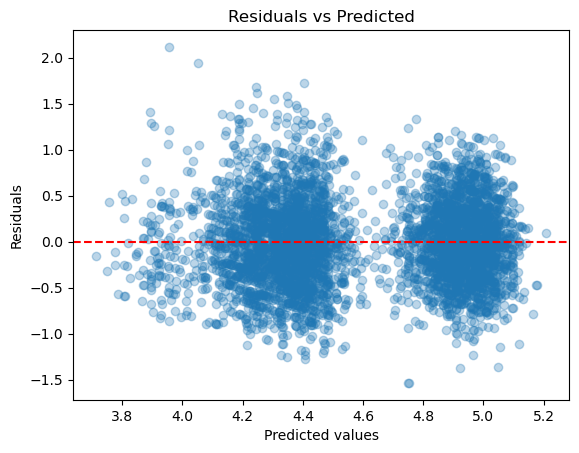

In [121]:
y_pred= model9.predict(X_test)
residuals= y_test - y_pred
plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted")
plt.show()

#### **Normality**

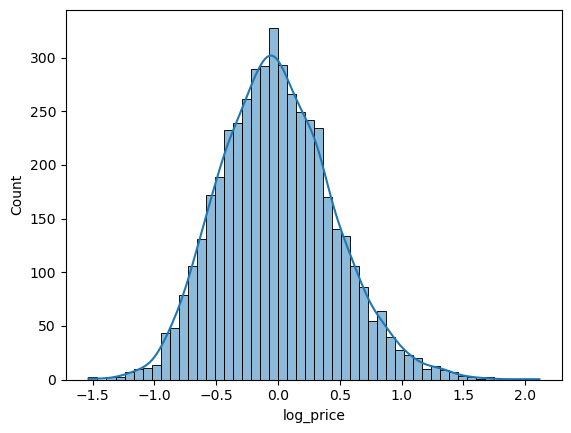

In [122]:
sns.histplot(residuals, kde=True)
plt.show()

#### **Homoscedasticity**

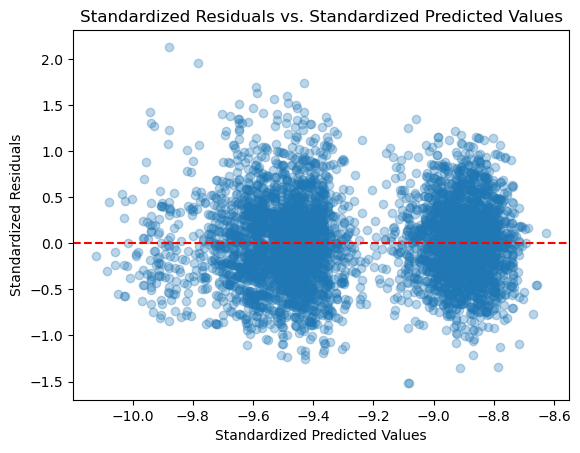

In [123]:
y_pred= model9.predict(X_test)
residuals= np.array(y_test) - np.array(y_pred)
standardized_residuals= residuals - np.mean(residuals) / np.std(residuals)
standardized_predicted_values= np.array(y_pred) - np.mean(y_pred) / np.std(y_pred)
plt.scatter(standardized_predicted_values, standardized_residuals, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Standardized Predicted Values")
plt.ylabel("Standardized Residuals")
plt.title("Standardized Residuals vs. Standardized Predicted Values")
plt.show()

#### **Multicollinearity**

In [124]:
num_cols= data.select_dtypes(['int64','float64']).columns.tolist() 
vif= pd.DataFrame(
    {'Variable': data[num_cols].columns,
     'VIF': [variance_inflation_factor(data[num_cols].values, i) for i in range(data[num_cols].shape[1]) ]
    }
)
vif

,Variable,VIF
0,accommodates,4.983203
1,bathrooms,0.000000
2,review_scores_rating,1.019612
3,bedrooms,0.000000
4,beds,1.519319
5,log_price,1.193406
6,total_rooms,0.000000
7,bathrooms_per_guest,4.152557


#### **Conclusion**

- The model explains less variance in the independence variable but the model generalizes well to the test data.
- The variables accommodates, review_scores_rating and beds have higher importance in predicting the price of the accommodation.

### **Business Recommendations:**

- Accomodations with more accommodates, bathrooms and bedrooms justify for higher rent price for the accommodation.
  
- Since, review_scores_rating has significant impact on rent, Airbnb can encourage customers for giving ratings and feedback.

- Airbnb can give incentives to get more ratings like points program which can be later used to get discounts on bookings.

- Hosts can focus on improving amenities and provide flexible cancellation policy.

- On higher end of the accomodations which are priced higher, model is unable to capture the reasons.

- Given features are explaining very less variance in the independent variables. Airbnb can try to capture more influential variables such as location, season, amenities, time_of_booking etc to capture more variance with the given model.